# Focused Sinhala MT visualizations

This notebook keeps only the six figures needed for the submission. It reads the two CSV files from `data/`, draws the selected visualizations, and saves PDF files in `results/`.


In [1]:
from pathlib import Path
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
import seaborn as sns
from scipy.stats import spearmanr

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
})

DATA_DIR = Path("data")
RESULTS_DIR = Path("results")
if RESULTS_DIR.resolve().parent != Path.cwd().resolve() or RESULTS_DIR.name != "results":
    raise RuntimeError("Refusing to clean an unexpected results directory.")
if RESULTS_DIR.exists():
    shutil.rmtree(RESULTS_DIR)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

BROAD_FILE = "Sinhala MT Human Annotations Results(1).csv"
DETAIL_FILE = "Sinhala MT Human Annotations Results Detailed (1)(1).csv"
broad_raw = pd.read_csv(DATA_DIR / BROAD_FILE)
detail_raw = pd.read_csv(DATA_DIR / DETAIL_FILE)

PRIMARY = ["Faithful", "Omission", "Mistranslation", "Degenerated Repetitive Output", "Hallucination"]
SUBTYPES = [
    "Extraneous hallucination",
    "Repetition",
    "Detached hallucination",
    "Partial Hallucination",
    "Incorrect target language / untranslated content",
    "Other",
]
D = "Degenerated Repetitive Output"
H = "Hallucination"
HD = "H + D"
DOMAINS = ["News", "Legal", "Cultural", "General"]
TOPICS = [
    "Accident", "Health", "Politics", "Sports", "Crime", "Disaster",
    "Economy and business", "Science and technology", "Society",
    "Entertainment", "Travel", "Environment",
]

ALIASES = {
    "gemini-3.6-flash": "Gemini 3.6 Flash",
    "gemini-3.1-pro": "Gemini 3.1 Pro",
    "gpt-5.5": "GPT-5.5",
    "Claude-Sonnet-4.6-thinking": "Claude Sonnet 4.6",
    "claude-opus-4.6-thinking": "Claude Opus 4.6",
    "llama-4-maverick-17B": "Llama 4 Maverick",
    "llama-3.1-8b-instruct": "Llama 3.1 8B",
    "llama-3.1-70b-instruct": "Llama 3.1 70B",
    "deepseek-v4-pro-0813": "DeepSeek V4 Pro",
    "deepseek-v4-flash-0731": "DeepSeek V4 Flash",
    "google-translate": "Google Translate",
    "qwen3.5-9b": "Qwen 3.5 9B",
    "qwen3.5-27b": "Qwen 3.5 27B",
    "mistral-large-2512": "Mistral Large 2512",
    "facebook/nllb-200-distilled-600M": "NLLB 600M",
    "google/madlad400-3b-mt": "MADLAD-400 3B",
    "Qwen/Qwen3.5-4B": "Qwen 3.5 4B",
}
SHORT_LABELS = {
    "Faithful": "Faithful",
    "Omission": "Omission",
    "Mistranslation": "Mistranslation",
    D: "Degeneration",
    H: "Hallucination",
    HD: "H + D",
    SUBTYPES[0]: "Extra-\nneous",
    SUBTYPES[1]: "Repe-\ntition",
    SUBTYPES[2]: "Detached",
    SUBTYPES[3]: "Partial",
    SUBTYPES[4]: "Wrong lang. /\nuntranslated",
    SUBTYPES[5]: "Other",
}
COLORS = {
    "Faithful": "#21847a",
    "Omission": "#e0a44a",
    "Mistranslation": "#5683b6",
    D: "#8b5ca6",
    H: "#ce5263",
    "Unaccounted": "#aeb8c3",
}
DOMAIN_COLORS = {
    "News": "#3274A1",
    "Legal": "#D24D57",
    "Cultural": "#238B7E",
    "General": "#D88928",
}
BASELINES = {"google-translate", "facebook/nllb-200-distilled-600M", "google/madlad400-3b-mt"}

def family(model):
    lower = model.lower()
    if model in BASELINES:
        return "Dedicated MT"
    if lower.startswith(("gemini", "gpt", "claude")):
        return "Closed-source"
    return "Open-weight"

def recover_counts(df):
    out = df.copy()
    for col in PRIMARY + SUBTYPES:
        out[col] = np.rint(out["Size"] * out[col] / 100).astype(int)
    out[HD] = out[H] + out[D]
    out["Unaccounted"] = out["Size"] - out[PRIMARY].sum(axis=1)
    out["Alias"] = out["Model"].map(ALIASES)
    out["System type"] = out["Model"].map(family)
    return out

broad = recover_counts(broad_raw)
detail = recover_counts(detail_raw)

model = broad.groupby("Model")[["Size"] + PRIMARY + [HD, "Unaccounted"]].sum()
for label in PRIMARY + [HD, "Unaccounted"]:
    model[label + " %"] = 100 * model[label] / model["Size"]
model["Alias"] = model.index.map(ALIASES)
model["System type"] = model.index.map(family)
model = model.sort_values(["Faithful %", "Hallucination %"], ascending=[False, True])
ORDER = model.index.tolist()

topic_n = detail.loc[detail["Category"].isin(TOPICS)].groupby("Category")["Size"].first()

def save_pdf(fig, filename):
    path = RESULTS_DIR / filename
    fig.tight_layout()
    fig.savefig(path, format="pdf", bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)
    print(f"saved {path}")

print("Loaded", len(broad), "broad rows and", len(detail), "detailed rows.")
print("PDF outputs will be saved in:", RESULTS_DIR.resolve())


Loaded 68 broad rows and 255 detailed rows.
PDF outputs will be saved in: C:\1 Disk D\Research\MT Working\sinhala_mt_analysis_updated\submission\results


## 1. Faithfulness by domain


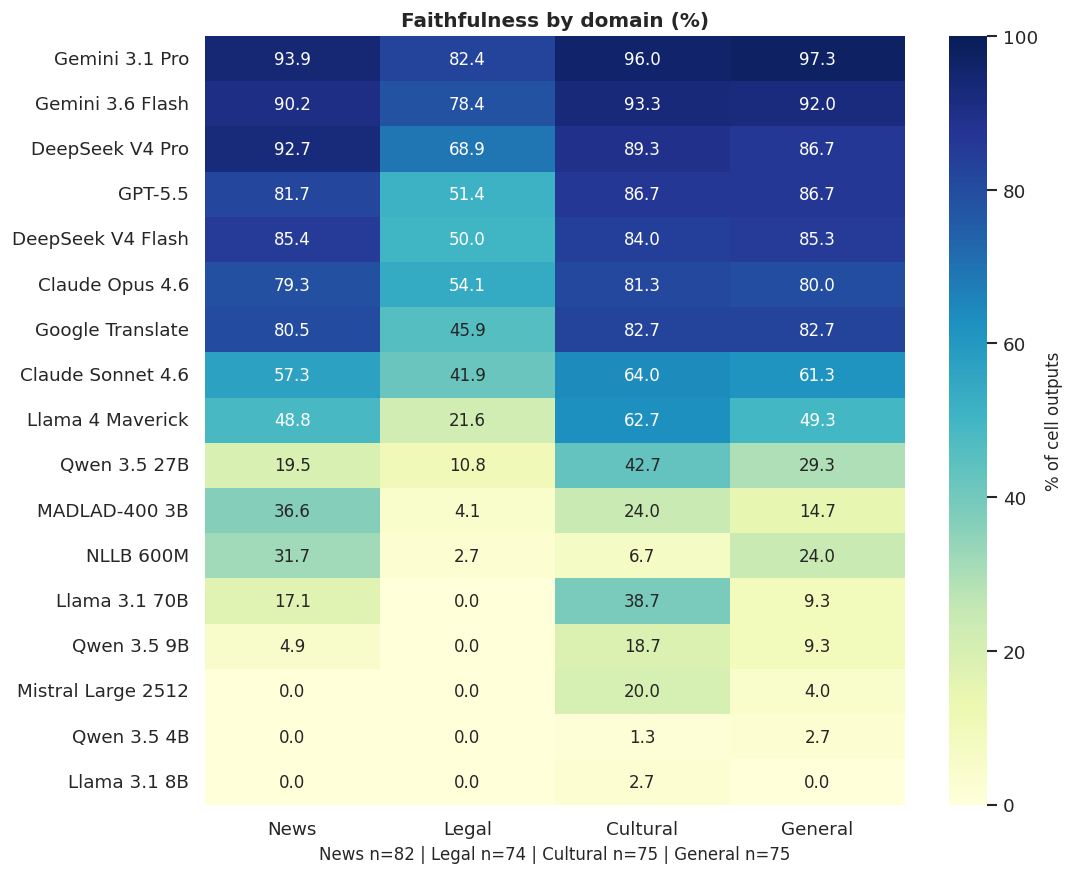

saved results\01_faithfulness_by_domain.pdf


In [2]:
values = (
    broad.assign(rate=100 * broad["Faithful"] / broad["Size"])
    .pivot(index="Model", columns="Category", values="rate")
    .reindex(index=ORDER, columns=DOMAINS)
)

fig, ax = plt.subplots(figsize=(9.2, 7.4))
sns.heatmap(
    values.rename(index=ALIASES),
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    ax=ax,
    cbar_kws={"label": "% of cell outputs"},
)
ax.set(
    title="Faithfulness by domain (%)",
    xlabel="News n=82 | Legal n=74 | Cultural n=75 | General n=75",
    ylabel="",
)
save_pdf(fig, "01_faithfulness_by_domain.pdf")


## 2. Primary-label composition


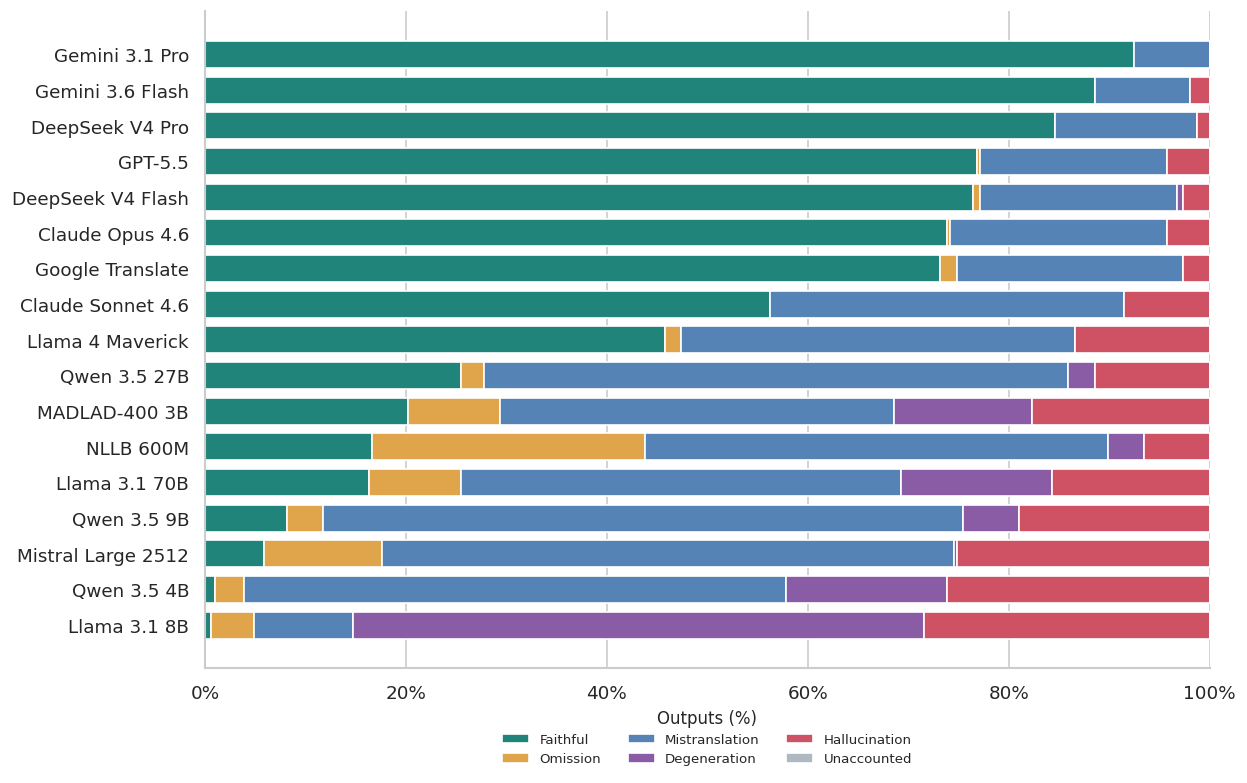

saved results\02_primary_label_composition.pdf


In [3]:
fig, ax = plt.subplots(figsize=(10.5, 6.6))
y = np.arange(len(model))
left = np.zeros(len(model))

for label in PRIMARY + ["Unaccounted"]:
    vals = model[label + " %"].values
    ax.barh(y, vals, left=left, color=COLORS[label], label=SHORT_LABELS.get(label, label), height=0.75)
    left += vals

ax.set_yticks(y, model["Alias"])
ax.invert_yaxis()
ax.set(xlim=(0, 100), xlabel="Outputs (%)")
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.08), frameon=False, fontsize=8)
save_pdf(fig, "02_primary_label_composition.pdf")


## 3. Hallucination subtype counts by domain


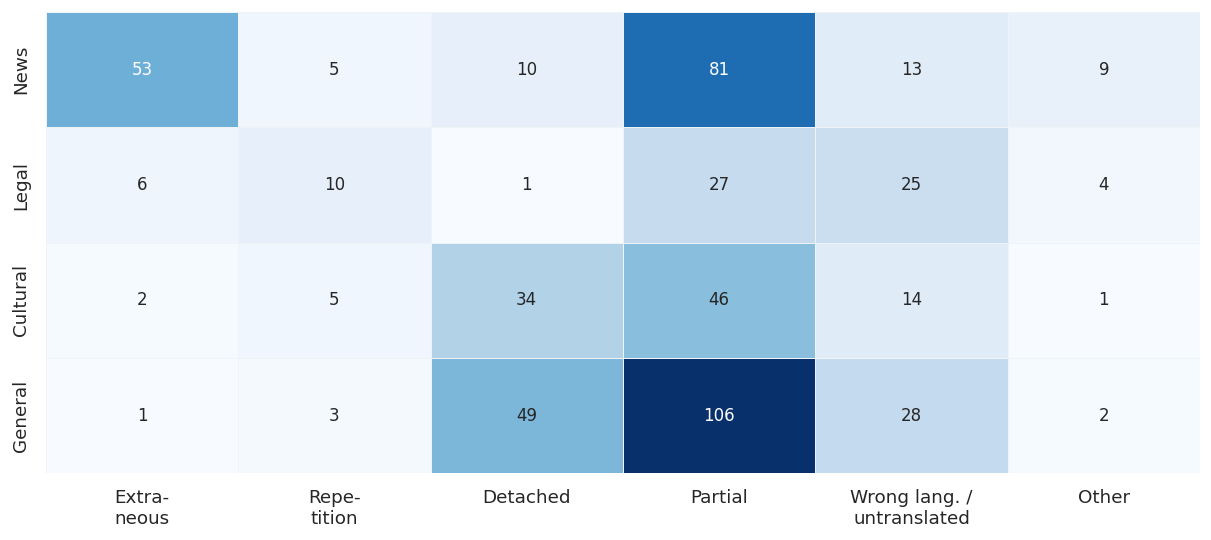

saved results\03_subtype_counts_by_domain.pdf


In [4]:
subdomain = broad.groupby("Category")[SUBTYPES].sum().reindex(DOMAINS)

fig, ax = plt.subplots(figsize=(10.2, 4.6))
sns.heatmap(
    subdomain.rename(columns=SHORT_LABELS),
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    ax=ax,
    linewidths=0.5,
    linecolor="#eef3f7",
)
ax.set(xlabel="", ylabel="")
ax.tick_params(axis="x", rotation=0)
save_pdf(fig, "03_subtype_counts_by_domain.pdf")


## 4. Size-labelled model profiles


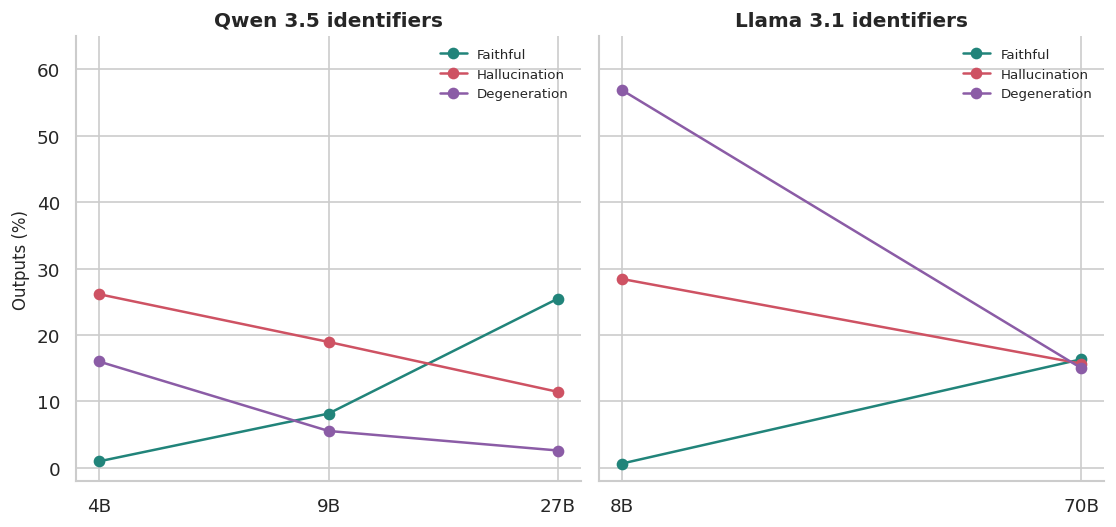

saved results\04_size_identifier_profiles.pdf


In [5]:
families = [
    (["Qwen/Qwen3.5-4B", "qwen3.5-9b", "qwen3.5-27b"], ["4B", "9B", "27B"], "Qwen 3.5 identifiers"),
    (["llama-3.1-8b-instruct", "llama-3.1-70b-instruct"], ["8B", "70B"], "Llama 3.1 identifiers"),
]

fig, axes = plt.subplots(1, 2, figsize=(9.4, 4.5), sharey=True)
for ax, (names, labels, title) in zip(axes, families):
    for metric in ["Faithful", H, D]:
        ax.plot(
            range(len(names)),
            model.loc[names, metric + " %"],
            marker="o",
            label=SHORT_LABELS[metric],
            color=COLORS[metric],
        )
    ax.set_xticks(range(len(names)), labels)
    ax.set(title=title, ylim=(-2, 65))
    ax.legend(fontsize=8, frameon=False, loc="upper right")
axes[0].set_ylabel("Outputs (%)")
save_pdf(fig, "04_size_identifier_profiles.pdf")


## 5. General-topic faithfulness


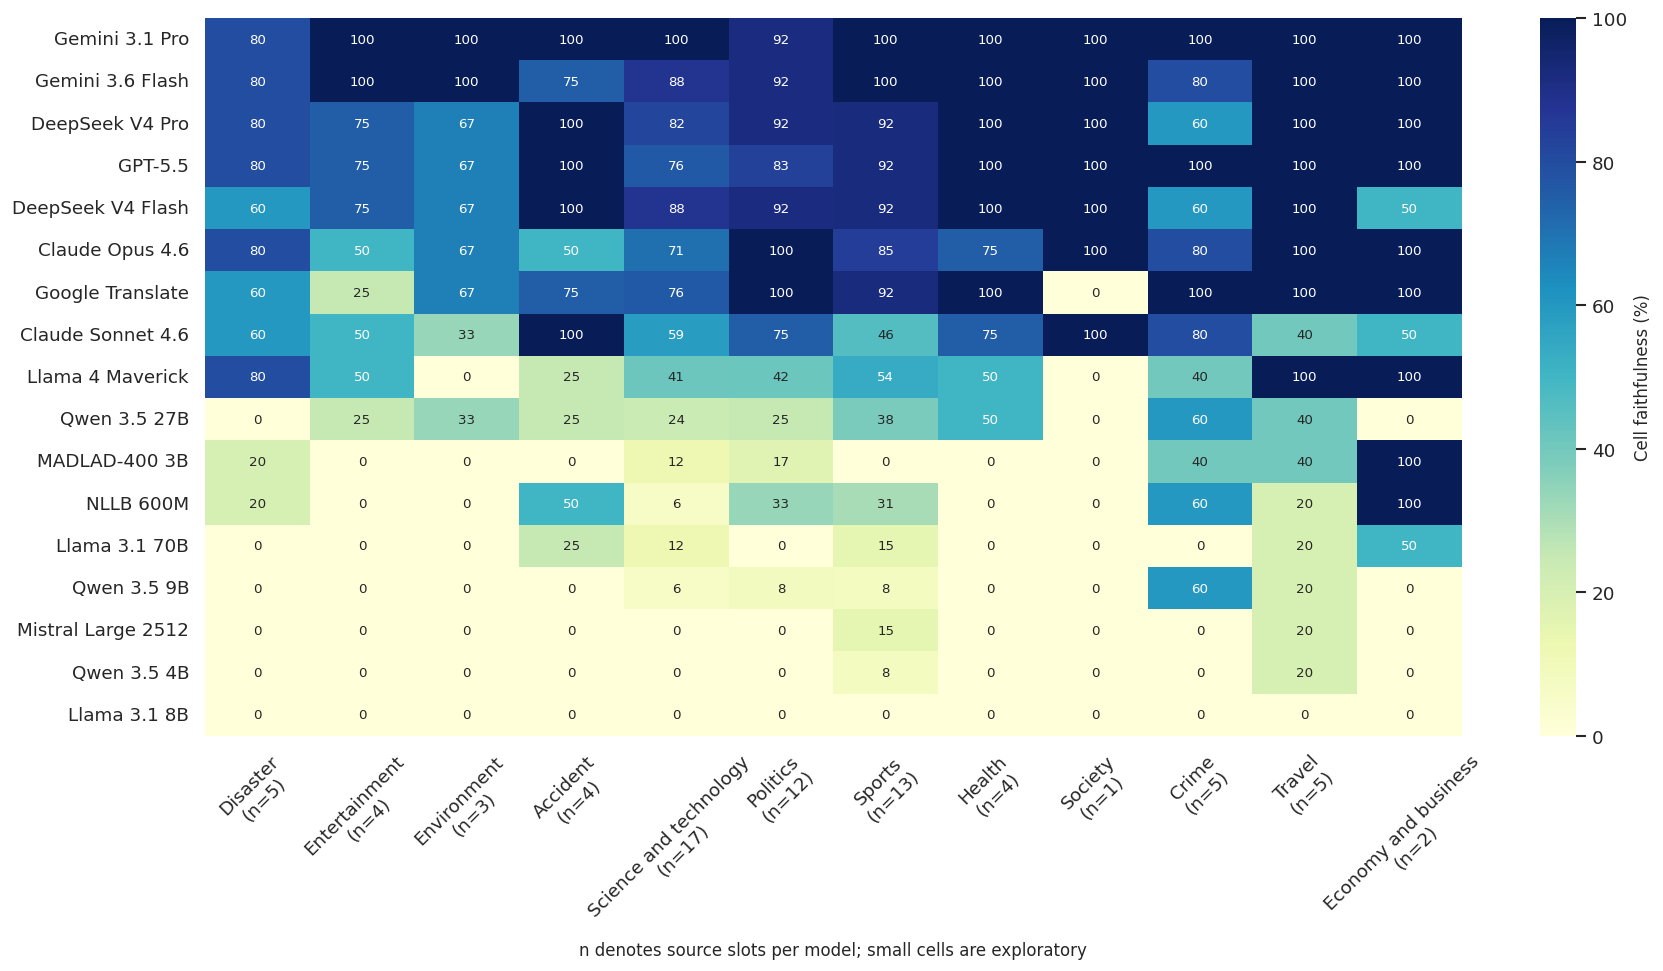

saved results\05_topic_faithfulness_heatmap.pdf


In [6]:
topics_summary = detail.loc[detail["Category"].isin(TOPICS)].groupby("Category")[["Size", "Faithful", H, HD]].sum()
topics_summary["Hallucination %"] = 100 * topics_summary[H] / topics_summary["Size"]
topic_order = topics_summary["Hallucination %"].sort_values(ascending=False).index.tolist()

td = detail.loc[detail["Category"].isin(TOPICS)].copy()
td["Rate"] = 100 * td["Faithful"] / td["Size"]
matrix = td.pivot(index="Model", columns="Category", values="Rate").reindex(index=ORDER, columns=topic_order)
matrix.columns = [f"{x}\n(n={topic_n[x]})" for x in matrix.columns]

fig, ax = plt.subplots(figsize=(15, 8.2))
sns.heatmap(
    matrix.rename(index=ALIASES),
    annot=True,
    fmt=".0f",
    annot_kws={"fontsize": 8},
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    ax=ax,
    cbar_kws={"label": "Cell faithfulness (%)"},
)
ax.set(xlabel="n denotes source slots per model; small cells are exploratory", ylabel="")
ax.tick_params(axis="x", rotation=45)
save_pdf(fig, "05_topic_faithfulness_heatmap.pdf")


## 6. Automatic metric alignment


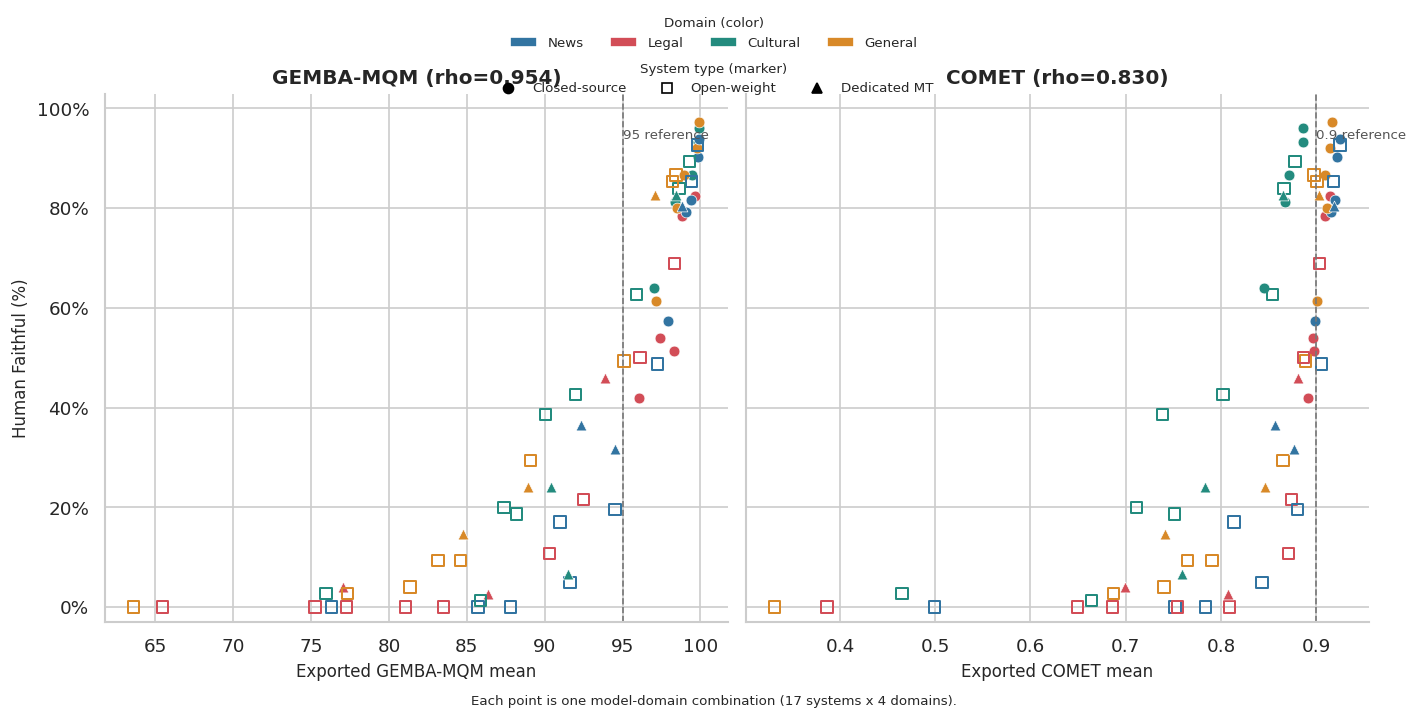

saved results\06_automatic_metric_alignment.pdf


In [7]:
cell = broad[["Model", "Alias", "Category", "Size", "System type", "Average gemba mqm score", "Average comet score", "Faithful"]].copy()
cell["Human Faithful (%)"] = 100 * cell["Faithful"] / cell["Size"]

type_styles = {
    "Closed-source": {"marker": "o", "face": "full"},
    "Open-weight": {"marker": "s", "face": "none"},
    "Dedicated MT": {"marker": "^", "face": "full"},
}
metric_specs = [
    ("Average gemba mqm score", "Exported GEMBA-MQM mean", "GEMBA-MQM", 95),
    ("Average comet score", "Exported COMET mean", "COMET", 0.90),
]

fig, axes = plt.subplots(1, 2, figsize=(12, 5.4), sharey=True)
for ax, (metric, xlabel, title, reference) in zip(axes, metric_specs):
    rho = spearmanr(cell[metric], cell["Human Faithful (%)"]).statistic
    for _, row in cell.iterrows():
        style = type_styles[row["System type"]]
        color = DOMAIN_COLORS[row["Category"]]
        if style["face"] == "none":
            ax.scatter(row[metric], row["Human Faithful (%)"], marker=style["marker"], s=46,
                       facecolors="none", edgecolors=color, linewidths=1.2)
        else:
            ax.scatter(row[metric], row["Human Faithful (%)"], marker=style["marker"], s=42,
                       color=color, edgecolors="white", linewidths=0.4)
    ax.axvline(reference, color="#777777", linestyle="--", linewidth=1)
    ax.text(reference, 96, f"{reference:g} reference", ha="left", va="top", fontsize=8, color="#555555")
    ax.set(title=f"{title} (rho={rho:.3f})", xlabel=xlabel, ylim=(-3, 103))
    ax.yaxis.set_major_formatter(PercentFormatter(100))
axes[0].set_ylabel("Human Faithful (%)")

domain_handles = [Patch(facecolor=color, label=domain) for domain, color in DOMAIN_COLORS.items()]
type_handles = [
    Line2D([0], [0], marker="o", color="black", linestyle="", label="Closed-source", markersize=6),
    Line2D([0], [0], marker="s", color="black", linestyle="", label="Open-weight", markersize=6, markerfacecolor="none"),
    Line2D([0], [0], marker="^", color="black", linestyle="", label="Dedicated MT", markersize=6),
]
fig.legend(handles=domain_handles, title="Domain (color)", loc="upper center", ncol=4,
           bbox_to_anchor=(0.5, 1.07), frameon=False, fontsize=8, title_fontsize=8)
fig.legend(handles=type_handles, title="System type (marker)", loc="upper center", ncol=3,
           bbox_to_anchor=(0.5, 1.0), frameon=False, fontsize=8, title_fontsize=8)
fig.text(0.5, -0.01, "Each point is one model-domain combination (17 systems x 4 domains).", ha="center", fontsize=8)
save_pdf(fig, "06_automatic_metric_alignment.pdf")
